### 워드문서 기록

In [7]:
# 로컬(.venv)에는 이미 설치되어 있다. 없으면 터미널에서:
# uv pip install langchain langchain_openai langchain_community langgraph


In [8]:
import os
from dotenv import load_dotenv

# 로컬에서는 Colab Secret 대신 프로젝트의 .env 파일에서 OPENAI_API_KEY 를 읽는다.
# (현재 폴더에 .env 가 없으면 상위 폴더에서 찾는다)
load_dotenv()
assert os.getenv("OPENAI_API_KEY"), ".env 에 OPENAI_API_KEY 가 없습니다."


In [9]:
# 로컬(.venv)에 설치 완료. 없으면 터미널에서:
# uv pip install python-docx


In [10]:
from docx import Document

doc = Document()
doc.add_heading('워드 테스트')
doc.add_paragraph( '안녕하세요 반갑습니다.')
doc.add_paragraph( '워드 문서 테스트')
doc.save("test.docx")

In [11]:
# 로컬(.venv)에 설치 완료. 없으면 터미널에서:
# uv pip install youtube-transcript-api


## 유튜브 자막추출

https://www.youtube.com/watch?v=vHdKMkIH7qM&t=2980s

In [12]:
from youtube_transcript_api import YouTubeTranscriptApi
video_id = 'vHdKMkIH7qM'  # 유튜브 비디오 ID
transcript = YouTubeTranscriptApi().fetch( video_id, languages=['ko','en'])  # 유튜브 비디오 ID
print(transcript.to_raw_data() )
text = " ".join( [item['text'] for item in transcript.to_raw_data() ] )
print( text )

IpBlocked: 
Could not retrieve a transcript for the video https://www.youtube.com/watch?v=vHdKMkIH7qM! This is most likely caused by:

YouTube is blocking requests from your IP. This usually is due to one of the following reasons:
- You have done too many requests and your IP has been blocked by YouTube
- You are doing requests from an IP belonging to a cloud provider (like AWS, Google Cloud Platform, Azure, etc.). Unfortunately, most IPs from cloud providers are blocked by YouTube.

Ways to work around this are explained in the "Working around IP bans" section of the README (https://github.com/jdepoix/youtube-transcript-api?tab=readme-ov-file#working-around-ip-bans-requestblocked-or-ipblocked-exception).


If you are sure that the described cause is not responsible for this error and that a transcript should be retrievable, please create an issue at https://github.com/jdepoix/youtube-transcript-api/issues. Please add which version of youtube_transcript_api you are using and provide th

## 유튜브 자막 추출 --> 요약 생성  --> word 파일로 저장

In [ ]:
from langchain_openai import ChatOpenAI
from youtube_transcript_api import YouTubeTranscriptApi
from docx import Document
from datetime import datetime

### Step 1:유튜브 자막추출
def extract_transcript_from_youtube( video_id ):
    transcript = YouTubeTranscriptApi().fetch( video_id, languages=['ko','en'])  # 유튜브 비디오 ID
    text = " ".join( [item['text'] for item in transcript.to_raw_data() ] )
    return text

def summarize_text( text ):
    chat = ChatOpenAI(model_name="gpt-4o-mini", temperature=0)
    prompt = f'다음 유튜브 자막을 한국어로 요약해줘:\n\n{text}'
    result = chat.invoke( prompt)
    return result.content

def save_summary_to_word(summary):
    doc = Document()
    doc.add_heading('유튜브 요약')
    doc.add_paragraph( summary )
    cur = datetime.now().strftime("%Y-%m-%d_%H_%M_%S")
    filename = f'summary_{cur}.docx'
    doc.save( filename)
    return filename

if __name__ == "__main__":
    video_id = 'dQw4w9WgXcQ'

    transcript_text = extract_transcript_from_youtube( video_id )
    summary_text = summarize_text( transcript_text )
    fname = save_summary_to_word( summary_text )
    print( "요약문서 저장완료:", fname )

요약문서 저장완료: summary_2025-09-08_20_24_42.docx


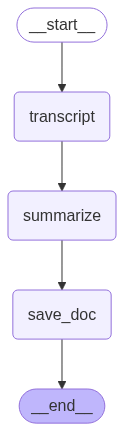

{'video_id': 'dQw4w9WgXcQ',
 'transcript': "[♪♪♪] ♪ We're no strangers to love ♪ ♪ You know the rules\nand so do I ♪ ♪ A full commitment's\nwhat I'm thinking of ♪ ♪ You wouldn't get this\nfrom any other guy ♪ ♪ I just wanna tell you\nhow I'm feeling ♪ ♪ Gotta make you understand ♪ ♪ Never gonna give you up ♪ ♪ Never gonna let you down ♪ ♪ Never gonna run around\nand desert you ♪ ♪ Never gonna make you cry ♪ ♪ Never gonna say goodbye ♪ ♪ Never gonna tell a lie\nand hurt you ♪ ♪ We've known each other\nfor so long ♪ ♪ Your heart's been aching\nbut you're too shy to say it ♪ ♪ Inside we both know\nwhat's been going ♪ ♪ We know the game\nand we're gonna play it ♪ ♪ And if you ask me\nhow I'm feeling ♪ ♪ Don't tell me\nyou're too blind to see ♪ ♪ Never gonna give you up ♪ ♪ Never gonna let you down ♪ ♪ Never gonna run around\nand desert you ♪ ♪ Never gonna make you cry ♪ ♪ Never gonna say goodbye ♪ ♪ Never gonna tell a lie\nand hurt you ♪ ♪ Never gonna give you up ♪ ♪ Never gonna let you do

In [ ]:
from langgraph.graph import StateGraph
from langchain_core.runnables import RunnableLambda
from langchain_openai import ChatOpenAI
from IPython.display import Image, display


# LLM 준비
llm = ChatOpenAI(model="gpt-4o-mini", temperature=0)

class MyState(dict):
    video_id: str
    transcript:str
    summary: str
    save_doc: str


def extract_transcript_from_youtube( state ):
    transcript = YouTubeTranscriptApi().fetch( state['video_id'], languages=['ko','en'])  # 유튜브 비디오 ID
    text = " ".join( [item['text'] for item in transcript.to_raw_data() ] )
    return {"transcript": text}

def summarize_text( state ):
    chat = ChatOpenAI(model_name="gpt-4o-mini", temperature=0)
    prompt = f"다음 유튜브 자막을 한국어로 요약해줘:\n\n{ state['transcript'] }"
    result = chat.invoke( prompt)
    return {'summary': result.content}

def save_summary_to_word( state):
    doc = Document()
    doc.add_heading('유튜브 요약')
    doc.add_paragraph( state['summary'] )
    cur = datetime.now().strftime("%Y-%m-%d_%H_%M_%S")
    filename = f'summary_{cur}.docx'
    doc.save( filename)
    return {'save_doc':filename}
# 그래프 만들기

graph = StateGraph(MyState)
graph.add_node("transcript", RunnableLambda(extract_transcript_from_youtube))
graph.add_node("summarize", RunnableLambda(summarize_text))
graph.add_node("save_doc", RunnableLambda(save_summary_to_word))

graph.set_entry_point("transcript")
graph.add_edge("transcript", "summarize")
graph.add_edge("summarize", "save_doc")
graph.set_finish_point("save_doc")

runnable = graph.compile()

display(Image(runnable.get_graph().draw_mermaid_png()))

video_id = 'dQw4w9WgXcQ'

#실행
result = runnable.invoke({"video_id":video_id})
result